# Benchmark Coverage Analysis

Three sections:
1. **MCP tool coverage** — which tools are tested, which are missing
2. **Benchmark composition** — tasks by category and by server
3. **Task browser** — searchable overview + per-task detail viewer

In [2]:
import json
import subprocess
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")
TASKS_FILE  = ROOT / "data" / "tasks" / "benchmark_tasks.json"
SKILL_SCRIPT = ROOT / ".claude" / "skills" / "eomcpevaluation" / "scripts" / "analyze_coverage.py"

CATEGORY_COLORS = {
    "Tool Grounding":       "#4c72b0",
    "Sequential Reasoning": "#dd8452",
    "Cross-agent Synthesis":"#55a868",
    "Scope Awareness":      "#c44e52",
}
SERVER_COLORS = {
    "eodashboard":      "#4c72b0",
    "gee-mcp":          "#55a868",
    "hybridrag":        "#dd8452",
    "moocs":            "#c44e52",
    "arxiv-mcp-server": "#8172b2",
    "gis-mcp":          "#64b5cd",
    "eve_retrieval":    "#ccb974",
}

print(f"Tasks file : {TASKS_FILE}")
print(f"Skill script: {SKILL_SCRIPT}")

Tasks file : ../data/tasks/benchmark_tasks.json
Skill script: ../.claude/skills/eomcpevaluation/scripts/analyze_coverage.py


---
## 1 — MCP Tool Coverage

In [3]:
# Run the coverage analysis script and parse its JSON output
result = subprocess.run(
    [sys.executable, str(SKILL_SCRIPT), str(ROOT)],
    capture_output=True, text=True
)
if result.returncode != 0:
    print("STDERR:", result.stderr)
    raise RuntimeError("analyze_coverage.py failed")

analysis = json.loads(result.stdout)
tc  = analysis["task_coverage"]
mc  = analysis["mcp_tool_coverage"]

print(f"Files scanned : {[Path(f).name for f in tc['_files_scanned']]}")
print(f"Total tasks   : {tc['_total_tasks']}")

Files scanned : ['benchmark_tasks.json']
Total tasks   : 294


In [4]:
# Build coverage DataFrame: one row per (server, tool)
rows = []
for server, info in mc.items():
    if not info["tools"]:
        rows.append({
            "Server": server,
            "Source": info["source"],
            "Tool": "—",
            "Active tasks": 0,
            "Covered": False,
            "Categories": "(no tools registered)",
        })
        continue
    for tool, td in info["tools"].items():
        rows.append({
            "Server": server,
            "Source": info["source"],
            "Tool": tool,
            "Active tasks": td["active_task_count"],
            "Covered": td["covered"],
            "Categories": ", ".join(td["categories"]) if td["categories"] else "—",
        })

df_cov = pd.DataFrame(rows)

def _color_covered(val):
    return "background-color: #d4edda" if val else "background-color: #f8d7da"

def _color_count(val):
    if val == 0:   return "color: #721c24"
    if val < 3:    return "color: #856404"
    return "color: #155724"

styled = (
    df_cov.style
    .map(_color_covered, subset=["Covered"])
    .map(_color_count,   subset=["Active tasks"])
    .set_caption("MCP Tool Coverage — green = covered, red = missing")
    .set_table_styles([{
        "selector": "caption",
        "props": [("font-size", "13px"), ("font-weight", "bold"), ("text-align", "left")]
    }])
    .hide(axis="index")
)
display(styled)

n_covered   = df_cov[df_cov["Tool"] != "—"]["Covered"].sum()
n_total     = (df_cov["Tool"] != "—").sum()
print(f"\nSummary: {n_covered}/{n_total} tools have at least one active task")
uncovered = df_cov[~df_cov["Covered"] & (df_cov["Tool"] != "—")][["Server", "Tool"]]
if len(uncovered):
    print("Uncovered tools:")
    print(uncovered.to_string(index=False))
else:
    print("All tools are covered.")

Server,Source,Tool,Active tasks,Covered,Categories
eodashboard,local,list_narratives,2,True,"Tool Grounding, Sequential Reasoning"
eodashboard,local,search_narratives,53,True,"Cross-agent Synthesis, Tool Grounding, Sequential Reasoning"
eodashboard,local,get_narrative_content,9,True,"Tool Grounding, Sequential Reasoning, Cross-agent Synthesis"
eodashboard,local,list_themes,2,True,Tool Grounding
eodashboard,local,get_narrative_indicators,0,False,—
eodashboard,local,search_collections,0,False,—
eodashboard,local,get_collection_items,0,False,—
eodashboard,local,find_narratives_for_indicator,2,True,Tool Grounding
gee-mcp,local,search_gee_catalog,1,True,Cross-agent Synthesis
gee-mcp,local,get_lat_lon,0,False,—



Summary: 63/72 tools have at least one active task
Uncovered tools:
     Server                       Tool
eodashboard   get_narrative_indicators
eodashboard         search_collections
eodashboard       get_collection_items
    gee-mcp                get_lat_lon
    gis-mcp            compute_s2_ndvi
    gis-mcp clip_raster_with_shapefile
    gis-mcp                  sjoin_gpd
    gis-mcp           point_in_polygon
    gis-mcp           zonal_statistics


---
## 2 — Benchmark Composition

In [5]:
# Load and flatten the benchmark tasks for analysis
raw = json.loads(TASKS_FILE.read_text())
tasks = raw["tasks"]

# Map each tool function name to its server
TOOL_TO_SERVER = {t: s for s, info in mc.items() for t in info["tools"]}

SERVER_OWNER = {
    "eodashboard":      "Eva",
    "eoss_graphrag":    "Eva",
    "arxiv-mcp-server": "Eva",
    "moocs":            "Eva",
    "cdse":             "Kaushik",
    "climate":          "Kaushik",
    "gee-mcp":          "Kaushik",
    "geos_ops":         "Riccardo",
}

def _owners(servers):
    seen = []
    for name in ("Eva", "Kaushik", "Riccardo"):
        if any(SERVER_OWNER.get(s) == name for s in servers):
            seen.append(name)
    return seen if seen else ["—"]

flat = []
for t in tasks:
    category = t["task_labels"][0] if t.get("task_labels") else "Unknown"
    fns = list({
        step["function_name"]
        for sol in (t.get("reference_solutions") or [])
        for step in sol.get("steps", [])
        if step.get("function_name")
    })
    servers = list({TOOL_TO_SERVER.get(fn, "unknown") for fn in fns})
    flat.append({
        "task_ID":  t["task_ID"],
        "category": category,
        "tools":    fns,
        "servers":  servers,
        "owners":   _owners(servers),
        "n_steps":  max((len(sol.get("steps", [])) for sol in (t.get("reference_solutions") or [])), default=0),
        "task_text": t["task_text"],
    })

df = pd.DataFrame(flat)
print(f"{len(df)} tasks loaded")

294 tasks loaded


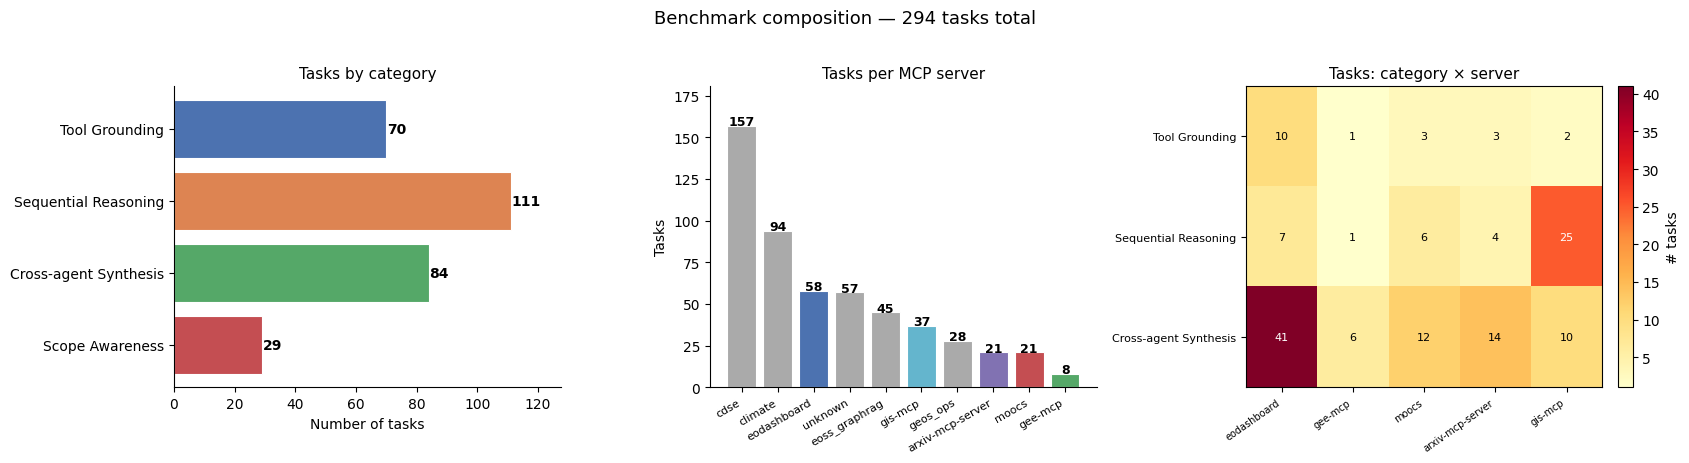

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# ── (A) Tasks by category ─────────────────────────────────────────────────
ax = axes[0]
cat_counts = df["category"].value_counts().reindex(CATEGORY_COLORS.keys()).dropna()
colors_a = [CATEGORY_COLORS.get(c, "#aaa") for c in cat_counts.index]
bars = ax.barh(cat_counts.index[::-1], cat_counts.values[::-1], color=colors_a[::-1],
               edgecolor="white", linewidth=0.8)
for bar, v in zip(bars, cat_counts.values[::-1]):
    ax.text(v + 0.3, bar.get_y() + bar.get_height() / 2,
            str(v), va="center", fontsize=10, fontweight="bold")
ax.set_xlabel("Number of tasks")
ax.set_title("Tasks by category", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, cat_counts.max() * 1.15)

# ── (B) Tasks by MCP server (exploded — task counted once per server) ─────
ax = axes[1]
server_rows = []
for _, row in df.iterrows():
    for srv in row["servers"]:
        server_rows.append({"server": srv, "task_ID": row["task_ID"]})
df_srv = pd.DataFrame(server_rows)
srv_counts = df_srv.groupby("server")["task_ID"].nunique().sort_values(ascending=False)
colors_b = [SERVER_COLORS.get(s, "#aaa") for s in srv_counts.index]
bars = ax.bar(srv_counts.index, srv_counts.values, color=colors_b,
              edgecolor="white", linewidth=0.8)
for bar, v in zip(bars, srv_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
            str(v), ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("Tasks")
ax.set_title("Tasks per MCP server", fontsize=11)
ax.set_xticks(range(len(srv_counts)))
ax.set_xticklabels(srv_counts.index, rotation=30, ha="right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, srv_counts.max() * 1.15)

# ── (C) Heatmap: category × server ───────────────────────────────────────
ax = axes[2]
heat_rows = []
for _, row in df.iterrows():
    for srv in row["servers"]:
        heat_rows.append({"category": row["category"], "server": srv})
df_heat = pd.DataFrame(heat_rows)
mat = df_heat.groupby(["category", "server"]).size().unstack(fill_value=0)
cat_order = [c for c in CATEGORY_COLORS if c in mat.index]
srv_order  = [s for s in SERVER_COLORS  if s in mat.columns]
mat = mat.reindex(index=cat_order, columns=srv_order, fill_value=0)

im = ax.imshow(mat.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(srv_order)))
ax.set_xticklabels(srv_order, rotation=35, ha="right", fontsize=7)
ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order, fontsize=8)
ax.set_title("Tasks: category × server", fontsize=11)
for r in range(mat.shape[0]):
    for c in range(mat.shape[1]):
        v = mat.values[r, c]
        ax.text(c, r, str(v) if v else "·", ha="center", va="center",
                fontsize=8, color="white" if v > mat.values.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.04, label="# tasks")

plt.suptitle(f"Benchmark composition — {len(df)} tasks total", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

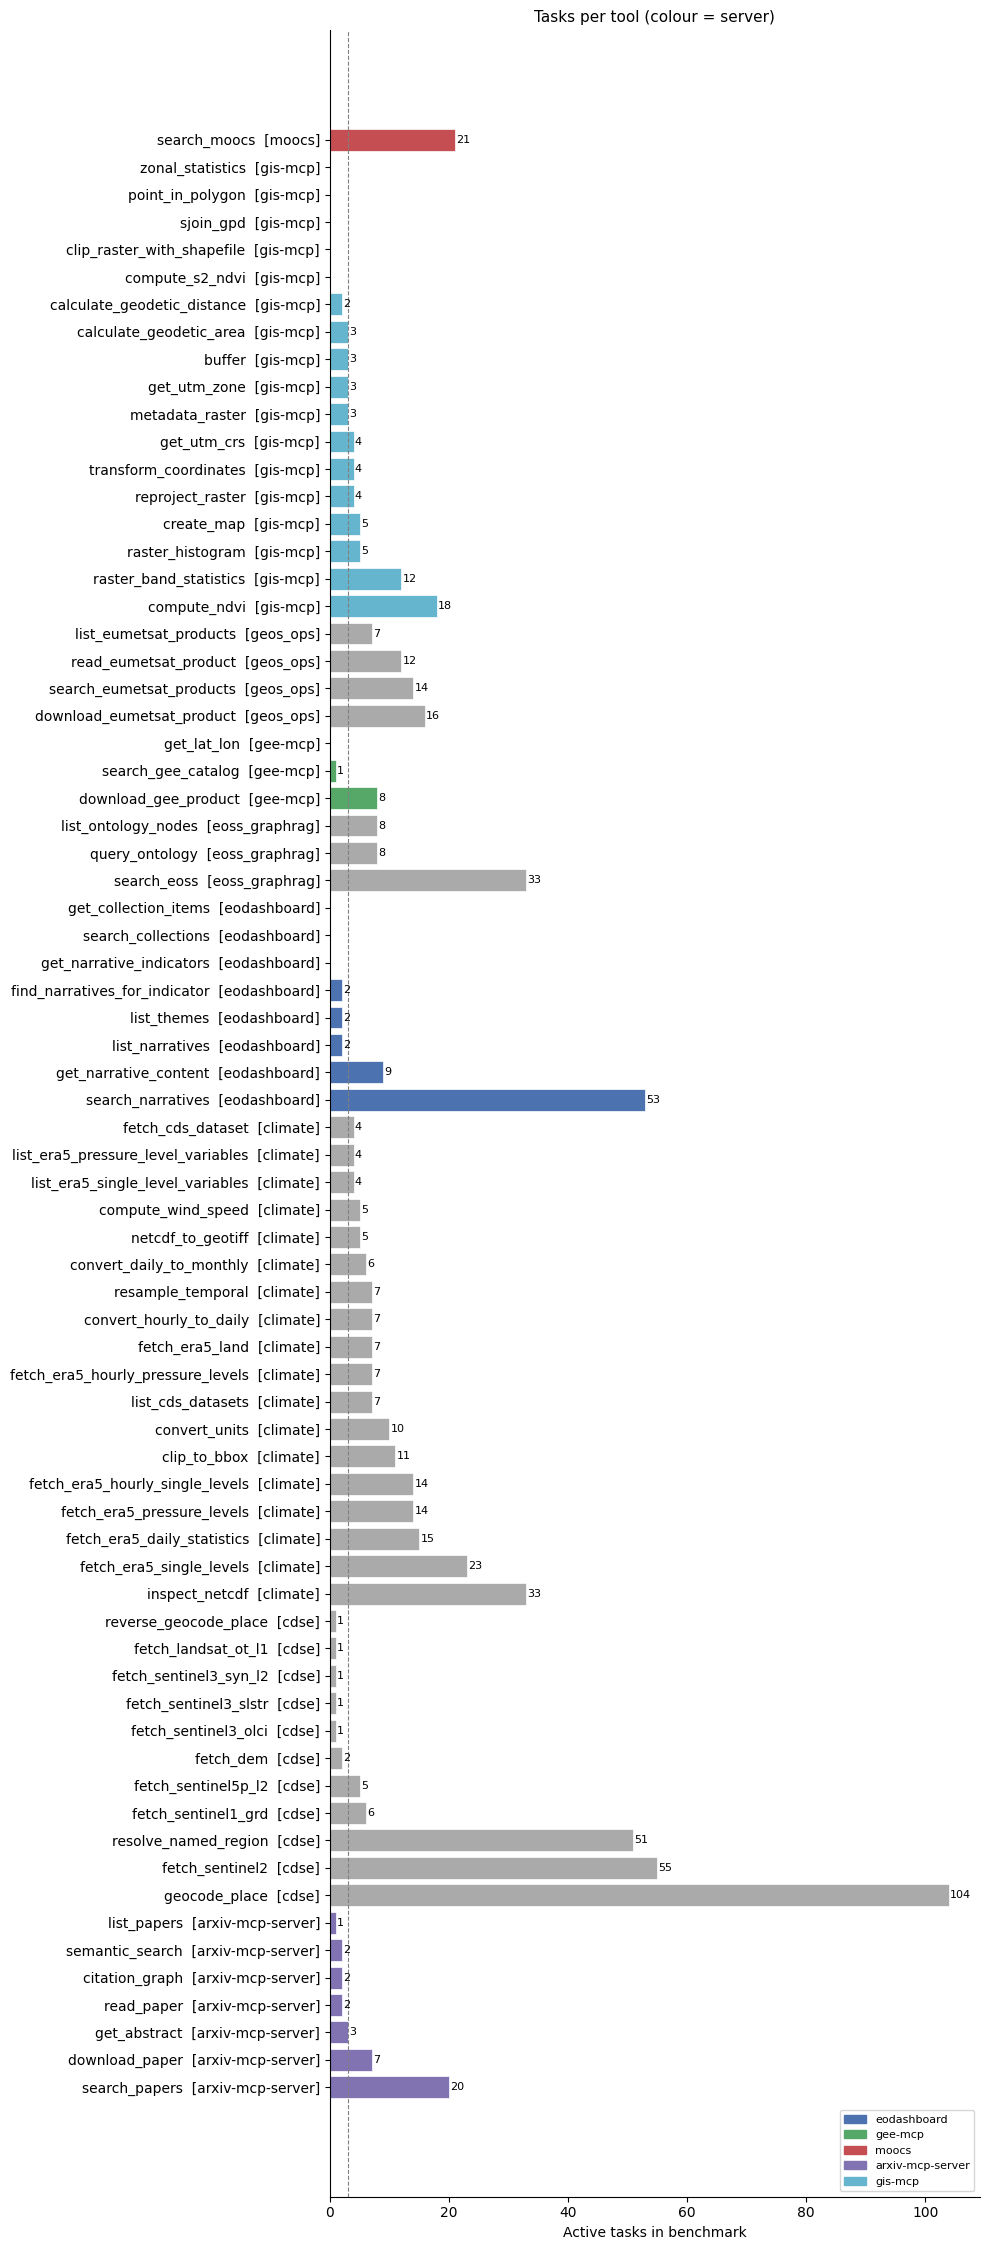

In [7]:
# Active tasks per tool (horizontal bar, grouped by server)
tool_data = [
    {"server": srv, "tool": t, "active_tasks": td["active_task_count"]}
    for srv, info in mc.items() for t, td in info["tools"].items()
]
df_tools = pd.DataFrame(tool_data).sort_values(["server", "active_tasks"], ascending=[True, False])

fig, ax = plt.subplots(figsize=(10, max(5, len(df_tools) * 0.3 + 1)))
bar_colors = [SERVER_COLORS.get(r["server"], "#aaa") for _, r in df_tools.iterrows()]
labels = [f"{r['tool']}  [{r['server']}]" for _, r in df_tools.iterrows()]
bars = ax.barh(labels, df_tools["active_tasks"], color=bar_colors,
               edgecolor="white", linewidth=0.5)
for bar, v in zip(bars, df_tools["active_tasks"]):
    if v > 0:
        ax.text(v + 0.2, bar.get_y() + bar.get_height() / 2,
                str(v), va="center", fontsize=8)
ax.set_xlabel("Active tasks in benchmark")
ax.set_title("Tasks per tool (colour = server)", fontsize=11)
ax.axvline(3, color="grey", linestyle="--", linewidth=0.8, label="min coverage threshold (3)")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
# Legend patches for servers
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=c, label=s) for s, c in SERVER_COLORS.items() if s in df_tools["server"].values]
ax.legend(handles=patches, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

---
## 3 — Task Browser

**Overview table** — filterable by category, server, or text search.  
**Detail viewer** — inspect any task by ID or keyword.

In [11]:
# ── Overview table ────────────────────────────────────────────────────────
OWNER_COLORS = {
    "Eva":      "#7b5ea7",
    "Kaushik":  "#2e7d5e",
    "Riccardo": "#c45c26",
}

# Build ordered call sequence per task (first reference solution only)
_task_calls = {}
for _t in tasks:
    _sols = _t.get("reference_solutions") or []
    _steps = _sols[0].get("steps", []) if _sols else []
    _fns = [s["function_name"] for s in _steps if s.get("function_name")]
    _task_calls[_t["task_ID"]] = "\n".join(f"{i+1}. {fn}" for i, fn in enumerate(_fns)) if _fns else "—"

# Ground-truth flag + reference solution description per task
_task_gt = {_t["task_ID"]: bool(_t.get("GT")) for _t in tasks}
_task_ref_desc = {_t["task_ID"]: (_t.get("reference_solution_description") or "—") for _t in tasks}

def _cat_color(val):
    c = CATEGORY_COLORS.get(val, "#eee")
    return f"background-color: {c}22; color: {c}; font-weight: bold"

def _owner_color(val):
    parts = [v.strip() for v in val.split(",")]
    colors = [OWNER_COLORS.get(p, "#888") for p in parts]
    color = colors[0]
    return f"color: {color}; font-weight: bold; white-space: nowrap"

def _gt_color(val):
    return ("background-color: #d4edda; color: #155724; font-weight: bold"
            if val else "background-color: #f8d7da; color: #721c24; font-weight: bold")

def show_overview(category=None, server=None, owner=None, text=None, ids=None):
    """Filter and display the task overview table.

    category: e.g. "Tool Grounding"
    server:   e.g. "moocs"
    owner:    "Eva", "Kaushik", "Riccardo"
    text:     substring search in task_text
    ids:      list of task_ID substrings to match
    """
    view = df.copy()
    if category:
        view = view[view["category"] == category]
    if ids:
        # view = view[view["task_ID"].str.contains("|".join(ids), case=False)]
        view = view[view["task_ID"].isin(ids)==True]
    if server:
        view = view[view["servers"].apply(lambda ss: server in ss)]
    if owner:
        view = view[view["owners"].apply(lambda oo: owner in oo)]
    if text:
        view = view[view["task_text"].str.contains(text, case=False)]

    display_df = view[["task_ID", "category", "owners", "servers", "task_text"]].copy()
    display_df["servers"] = display_df["servers"].apply(lambda x: ", ".join(sorted(x)))
    display_df["owners"]  = display_df["owners"].apply(lambda x: ", ".join(x))
    display_df["calls"]   = display_df["task_ID"].map(_task_calls)
    display_df["gt"]      = display_df["task_ID"].map(_task_gt)
    display_df["ref_desc"] = display_df["task_ID"].map(_task_ref_desc)
    display_df.columns    = ["ID", "Category", "Owner", "Servers", "Task", "Calls", "GT", "Reference Solution"]

    styled_view = (
        display_df.style
        .map(_cat_color, subset=["Category"])
        .map(_owner_color, subset=["Owner"])
        .map(_gt_color, subset=["GT"])
        .set_properties(subset=["Task"], **{
            "white-space": "normal", "word-wrap": "break-word",
            "min-width": "320px", "max-width": "560px", "line-height": "1.5",
        })
        .set_properties(subset=["Reference Solution"], **{
            "white-space": "normal", "word-wrap": "break-word",
            "min-width": "280px", "max-width": "480px", "line-height": "1.5",
            "font-size": "10px", "color": "#444",
        })
        .set_properties(subset=["Calls"], **{
            "white-space": "pre", "font-family": "monospace", "font-size": "10px",
            "line-height": "1.7", "min-width": "180px", "color": "#2a5a8a",
        })
        .set_properties(subset=["ID"], **{
            "font-family": "monospace", "font-size": "10px", "white-space": "nowrap",
        })
        .set_properties(subset=["Servers"], **{
            "font-size": "10px", "white-space": "nowrap", "color": "#555",
        })
        .set_properties(subset=["Category"], **{"white-space": "nowrap"})
        .set_properties(subset=["GT"], **{"white-space": "nowrap", "text-align": "center"})
        .set_caption(f"Showing {len(display_df)} / {len(df)} tasks")
        .set_table_styles([
            {"selector": "caption", "props": [("font-size", "12px"), ("font-weight", "bold"),
             ("text-align", "left"), ("padding-bottom", "6px")]},
            {"selector": "td", "props": [("font-size", "11px"), ("vertical-align", "top"),
             ("padding", "5px 10px")]},
            {"selector": "th", "props": [("font-size", "11px"), ("white-space", "nowrap"),
             ("text-align", "left"), ("padding", "5px 10px")]},
        ])
        .hide(axis="index")
    )
    display(styled_view)

# ── Filters — edit these and re-run the cell ──────────────────────────────
FILTER_CATEGORY = None          # e.g. "Tool Grounding"
FILTER_SERVER   = None          # e.g. "moocs"
FILTER_OWNER    = None          # "Eva", "Kaushik", "Riccardo", or None for all
FILTER_TEXT     = None          # e.g. "SAR"
FILTER_ID       =  ["300001", "300003", "200001", "200002", "200003", "200004", "200006", "200007", "500020", "500022", "500023", "500025", "500026", "500030", "50003"]

show_overview(FILTER_CATEGORY, FILTER_SERVER, FILTER_OWNER, FILTER_TEXT, FILTER_ID)

ID,Category,Owner,Servers,Task,Calls,GT,Reference Solution


In [9]:


def show_task(query: str):
    # Exact ID match first
    if query in task_map:
        t = task_map[query]
    else:
        # Keyword search in task_text
        matches = [t for t in tasks if query.lower() in t["task_text"].lower()]
        if not matches:
            print(f"No task found matching {query!r}")
            return
        if len(matches) > 1:
            print(f"{len(matches)} matches — showing first. Others: {[m['task_ID'] for m in matches[1:6]]}")
        t = matches[0]

    label   = t.get("task_labels", ["—"])
    servers = sorted({TOOL_TO_SERVER.get(step["function_name"], "?") 
                      for sol in (t.get("reference_solutions") or [])
                      for step in sol.get("steps", [])})

    print(f"{'━'*70}")
    print(f"  {t['task_ID']}  |  {', '.join(label)}  |  servers: {', '.join(servers)}")
    print(f"{'━'*70}")
    print(f"\n  {t['task_text']}\n")
    if t.get("reference_solution_description"):
        print(f"  ↳ {t['reference_solution_description']}\n")

    for r_idx, sol in enumerate(t.get("reference_solutions") or []):
        header = f"  Reference {r_idx+1}:" if len(t["reference_solutions"]) > 1 else "  Reference:"
        if not sol.get("steps"):
            print(f"{header} (no tool calls — correct answer is to not call any tool)")
            continue
        for i, step in enumerate(sol["steps"]):
            args = ", ".join(f"{k}={v!r}" for k, v in step.get("arguments", {}).items())
            prefix = header if i == 0 else " " * len(header)
            print(f"{prefix}  {i+1}. {step['function_name']}({args})")
            if step.get("comment"):
                print(f"{' ' * len(header)}     # {step['comment']}")

    if t.get("generated_solution") is not None:
        gen = t["generated_solution"]
        print(f"\n  Generated solution:")
        for i, step in enumerate(gen.get("steps") or []):
            args = ", ".join(f"{k}={v!r}" for k, v in step.get("arguments", {}).items())
            print(f"    {i+1}. {step['function_name']}({args})")
        score = t.get("match_score_LLM")
        if score is not None:
            print(f"  LLM score: {score}")
    print()


# ── Task detail viewer ────────────────────────────────────────────────────
# Set INSPECT to a task_ID string, or a keyword (shows first match)
INSPECT = "TASK_260619_000006_300006"   # ← change this

task_map = {t["task_ID"]: t for t in tasks}

show_task(INSPECT)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  TASK_260619_000006_300006  |  Cross-agent Synthesis  |  servers: ?, cdse, eoss_graphrag, moocs
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Search the ESA Science Strategy for priorities on glacier and cryosphere monitoring and search MOOC content for lectures on ice sheet remote sensing. Identify a glacier or cryosphere study site relevant to these sources, download a recent summer Sentinel-2 image of that location, and describe the visible cryosphere features that are relevant for monitoring climate change impacts.

  ↳ Search EOSS for cryosphere monitoring priorities and MOOCs for ice sheet remote sensing content. Use a glacier site identified from those results as the download target — geocode it, then download a Sentinel-2 RGB image for a cloud-free summer acquisition.

  Reference:  1. search_eoss(question='ESA Science Strategy cryosphere glacier ice sheet monitoring priorities')

In [10]:
# ── Browse all tasks grouped by category ─────────────────────────────────
# Set BROWSE_CATEGORY to see all tasks in one category, or None for all
BROWSE_CATEGORY = "Tool Grounding"   # ← change this

CATEGORY_ORDER = ["Tool Grounding", "Sequential Reasoning", "Cross-agent Synthesis", "Scope Awareness"]
cats_to_show = [BROWSE_CATEGORY] if BROWSE_CATEGORY else CATEGORY_ORDER

for cat in cats_to_show:
    group = [t for t in tasks if cat in (t.get("task_labels") or [])]
    if not group:
        continue
    print(f"\n{'━'*72}")
    print(f"  {cat}  ({len(group)} tasks)")
    print(f"{'━'*72}")
    for t in group:
        fns = [step["function_name"]
               for sol in (t.get("reference_solutions") or [])
               for step in sol.get("steps", [])]
        srvs = sorted({TOOL_TO_SERVER.get(fn, "?") for fn in fns})
        print(f"\n  [{t['task_ID']}]  servers: {', '.join(srvs)}")
        print(f"  {t['task_text']}")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Tool Grounding  (70 tasks)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  [TASK_260419_000001_100001]  servers: eodashboard
  List all available themes in the EO Dashboard.

  [TASK_260419_000003_100003]  servers: eodashboard
  Retrieve the full content of any narrative about air quality.

  [TASK_260419_000006_100006]  servers: eodashboard
  Which narratives in the EO Dashboard reference the indicator collection EO:EEA:DAT:CLMS_CORINE_CLCPLUS_RASTER_2018_V1_1?

  [TASK_260419_000009_100009]  servers: eodashboard
  Find an EO Dashboard narrative about forest cover loss and retrieve its full text content.

  [TASK_260419_000010_100010]  servers: eodashboard
  Which EO Dashboard narratives reference the sea ice dataset with indicator code EO:ESA:DAT:CRYOSAT:SEA_ICE_THICKNESS?

  [TASK_260419_000011_100011]  servers: eodashboard
  Get an overview of all thematic areas covered by the EO